In [1]:
import numpy as np  
import matplotlib.pyplot as plt
import os

In [2]:
OUTPUT_FOLDER = '/home/mnex/Desktop/1DV_FD/experiments/3_Lotus_realistic/output'
with np.load(os.path.join(OUTPUT_FOLDER, 'lotus_forcing.npz')) as forcing:
    ua  = forcing['ua']
    Qns = forcing['Q_ns']
    Qsw = forcing['Q_sw']
    dt  = float(forcing['dt'])
    
time = np.arange(ua.shape[1]) * dt / 86400          # days since 13 May 1982

def plot_with_envelope(ax, time, var_m, var_std, color=None, label=None):
    ax.plot(time, var_m, 
            color=color, label=label)
    ax.fill_between(time, 
                    var_m - var_std,
                    var_m + var_std,
                    color=color, alpha=0.3)

def daily_mean(var, dt):
    n_day = int(round(86400 / dt))
    n_full = (len(var) // n_day) * n_day
    return var[:n_full].reshape(-1, n_day).mean(axis=1), (np.arange(n_full // n_day) + 0.5)

/tmp/ipykernel_110622/2082543151.py:26: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  a.legend(loc='upper right')


(0.0, 159.97916666666666)

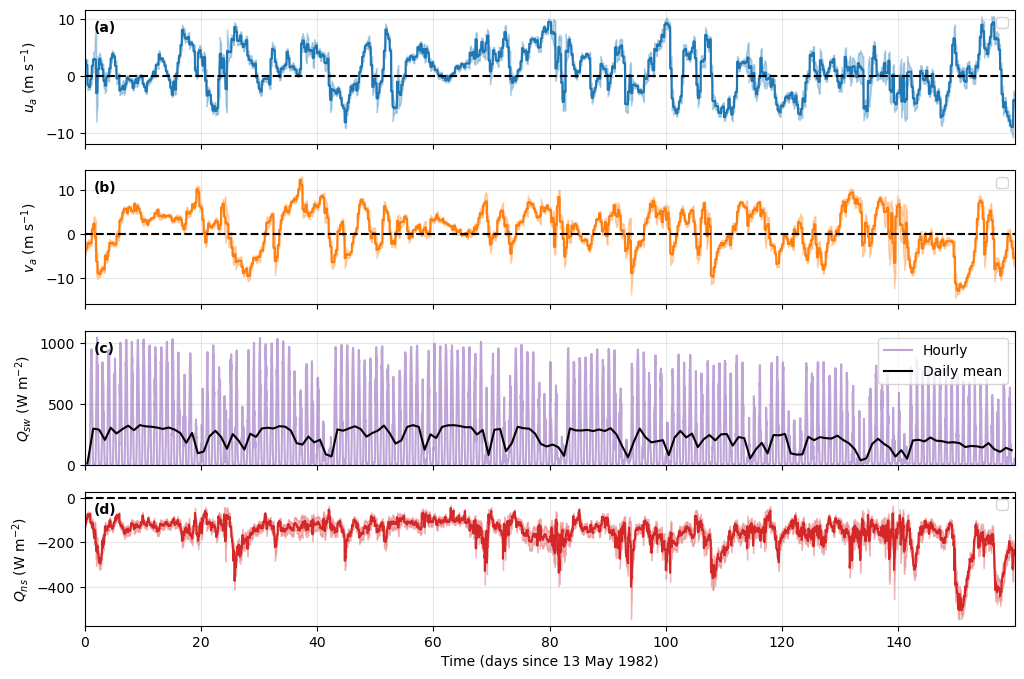

In [3]:
fig, ax = plt.subplots(4, 1, figsize=(12, 8), sharex=True)

# Zonal wind
plot_with_envelope(ax[0], time, ua.real.mean(0), ua.real.std(0), color='C0')
ax[0].set_ylabel(r'$u_a$ (m s$^{-1}$)')

# Meridional wind
plot_with_envelope(ax[1], time, ua.imag.mean(0), ua.imag.std(0), color='C1')
ax[1].set_ylabel(r'$v_a$ (m s$^{-1}$)')

# Net shortwave (deterministic) + daily mean
Qsw_day, t_day = daily_mean(Qsw, dt)
ax[2].plot(time, Qsw, color='C4', alpha=0.6, label='Hourly')
ax[2].plot(t_day, Qsw_day, color='k', label='Daily mean')
ax[2].set_ylabel(r'$Q_{sw}$ (W m$^{-2}$)')
ax[2].set_ylim(bottom=0)

# Non-solar heat flux (positive into the ocean)
plot_with_envelope(ax[3], time, Qns.mean(0), Qns.std(0), color='C3')
ax[3].set_ylabel(r'$Q_{ns}$ (W m$^{-2}$)')
ax[3].set_xlabel('Time (days since 13 May 1982)')

for a, letter in zip(ax, 'abcd'):
    a.grid(alpha=0.3)
    a.text(0.01, 0.92, f'({letter})', transform=a.transAxes, fontweight = 'bold', va='top')
    a.legend(loc='upper right')
    
for a in (ax[0], ax[1], ax[3]):
    a.axhline(0, color='k', ls='--')
ax[-1].set_xlim(time[0], time[-1])